# Effective visualizations

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA
from adjustText import adjust_text

from src.config import BrainRegions
from src.data.loader import load_all_regions, load_phenotypes
from src.config import L1_REGULATORS, L1_REGULATORS_WITH_2_STEPS_FROM_MECP2

In [2]:
df = load_phenotypes()
regions = load_all_regions(nrows=None)

In [3]:
expression = pd.concat([expr.set_index("Name").drop(columns="Description") for expr in regions.values()], axis=1).T

expression = expression.loc[:, expression.mean() >= 1]
expression = np.log2(expression + 1)
expression.shape

(3234, 17461)

In [4]:
pca = PCA(n_components=2, random_state=42)
components = pca.fit_transform(expression)

donors = expression.index.str.split("-").str[:2].str.join("-")
projection = pd.DataFrame({
    "PC1": components[:, 0],
    "PC2": components[:, 1],
    "SEX": donors.map(df.set_index("SUBJID")["SEX"].replace({1: "Male", 2: "Female"})),
})
pca.explained_variance_ratio_

array([0.48128758, 0.14520485])

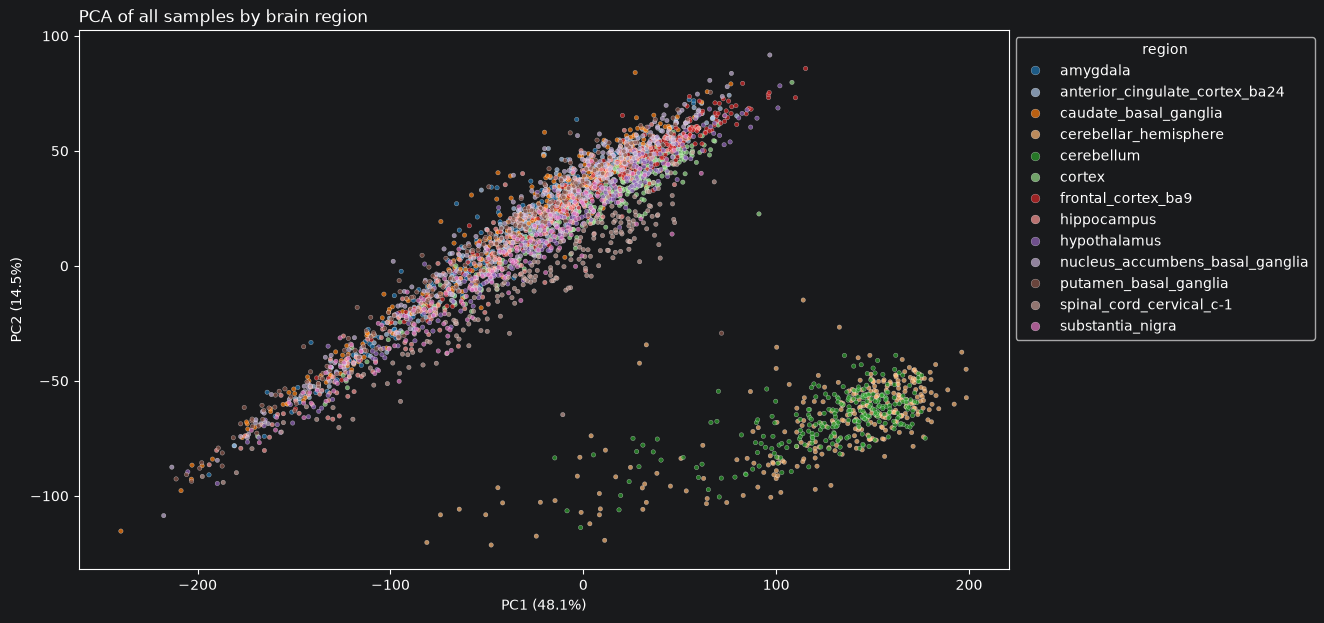

In [5]:
sample_region = {sample: region.value for region, expr in regions.items() for sample in expr.columns[2:]}
projection["region"] = expression.index.map(sample_region)

plt.figure(figsize=(12, 7))
sns.scatterplot(data=projection, x="PC1", y="PC2", hue="region", palette="tab20", s=10, alpha=0.7)
plt.xlabel(f"PC1 ({pca.explained_variance_ratio_[0]:.1%})")
plt.ylabel(f"PC2 ({pca.explained_variance_ratio_[1]:.1%})")
plt.title("PCA of all samples by brain region", loc="left")
plt.legend(title="region", bbox_to_anchor=(1, 1), markerscale=2)
plt.show()

In [6]:
from sklearn.manifold import TSNE
from umap import UMAP

pca_50 = PCA(n_components=50, random_state=42).fit_transform(expression)

tsne = TSNE(n_components=2, perplexity=30, random_state=42).fit_transform(pca_50)
umap = UMAP(n_components=2, n_neighbors=15, min_dist=0.1, random_state=42, n_jobs=1, compatibility_layout=True).fit_transform(pca_50)

projection["TSNE1"], projection["TSNE2"] = tsne[:, 0], tsne[:, 1]
projection["UMAP1"], projection["UMAP2"] = umap[:, 0], umap[:, 1]

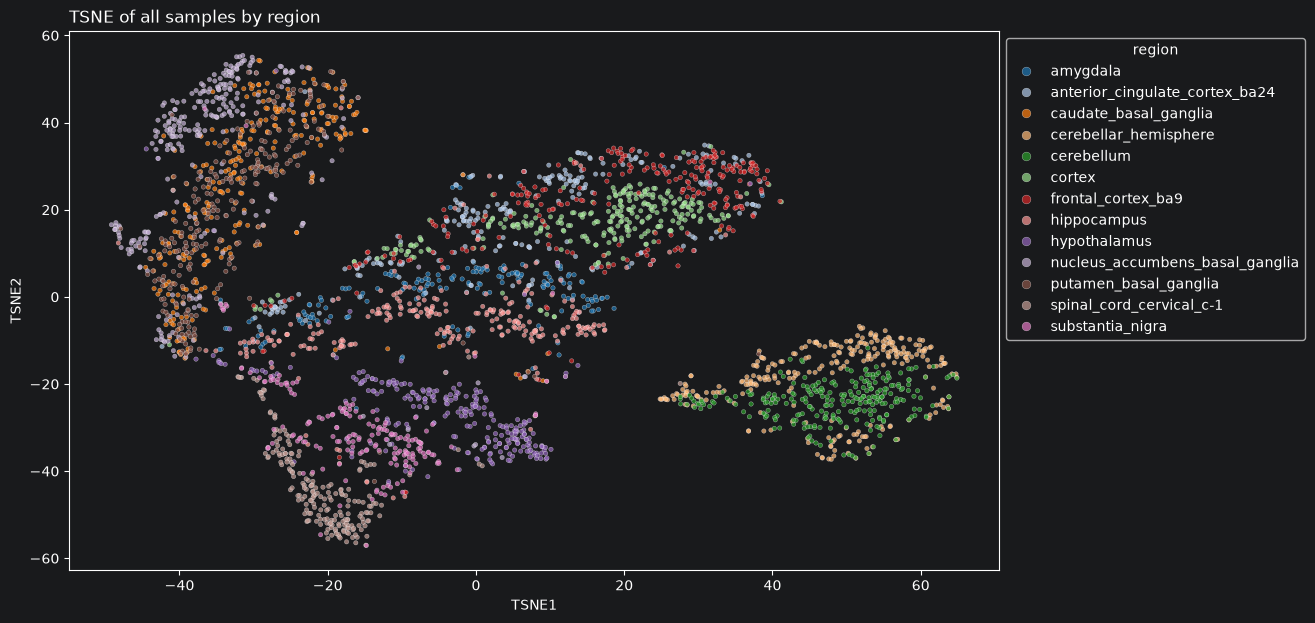

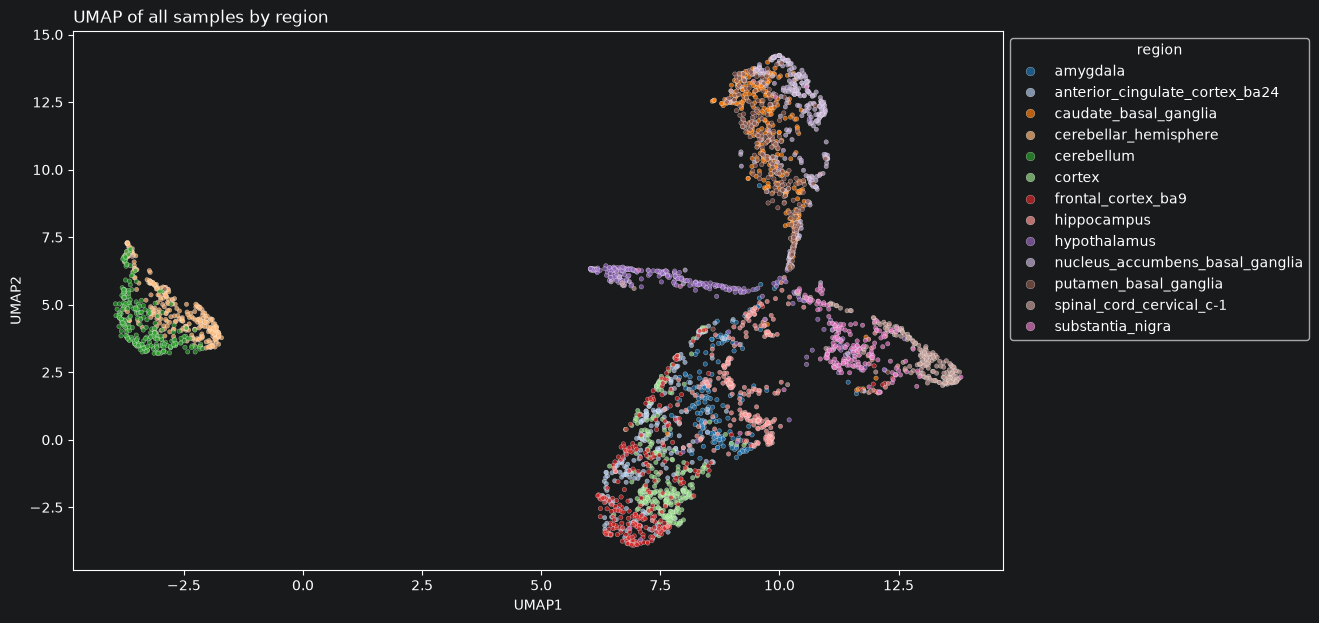

In [7]:
for method in ["TSNE", "UMAP"]:
    for hue, palette in [("region", "tab20")]:
        plt.figure(figsize=(12, 7))
        sns.scatterplot(data=projection, x=f"{method}1", y=f"{method}2", hue=hue, palette=palette, s=10, alpha=0.7)
        plt.title(f"{method} of all samples by {hue}", loc="left")
        plt.legend(title=hue, bbox_to_anchor=(1, 1), markerscale=2)
        plt.show()

## Regiões do cérebro e suas relações

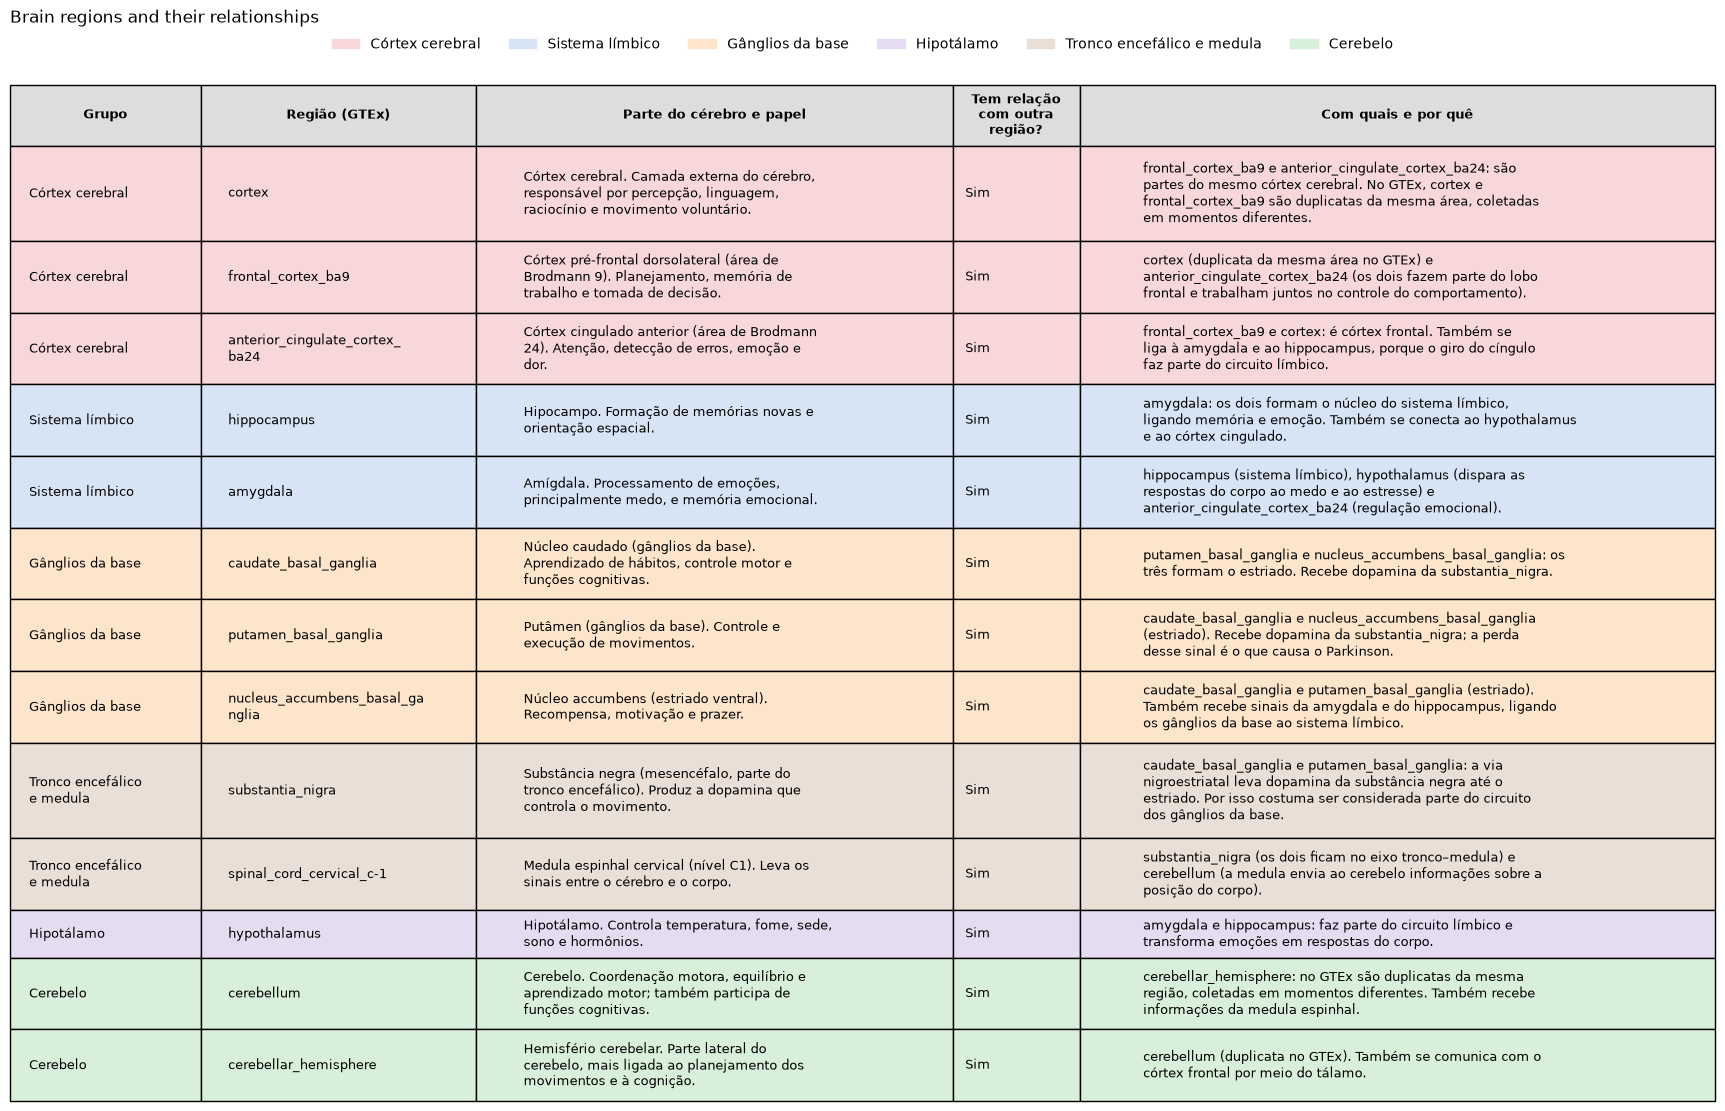

In [8]:
groups = {
    "Córtex cerebral": ("🔴", "#f8d7da"),
    "Sistema límbico": ("🔵", "#d6e4f5"),
    "Gânglios da base": ("🟠", "#fde5cc"),
    "Hipotálamo": ("🟣", "#e6dcf2"),
    "Tronco encefálico e medula": ("🟤", "#eadfd6"),
    "Cerebelo": ("🟢", "#d8efd9"),
}

brain_regions = pd.DataFrame([
    ["Córtex cerebral", "cortex",
     "Córtex cerebral. Camada externa do cérebro, responsável por percepção, linguagem, raciocínio e movimento voluntário.",
     "Sim", "frontal_cortex_ba9 e anterior_cingulate_cortex_ba24: são partes do mesmo córtex cerebral. No GTEx, cortex e frontal_cortex_ba9 são duplicatas da mesma área, coletadas em momentos diferentes."],
    ["Córtex cerebral", "frontal_cortex_ba9",
     "Córtex pré-frontal dorsolateral (área de Brodmann 9). Planejamento, memória de trabalho e tomada de decisão.",
     "Sim", "cortex (duplicata da mesma área no GTEx) e anterior_cingulate_cortex_ba24 (os dois fazem parte do lobo frontal e trabalham juntos no controle do comportamento)."],
    ["Córtex cerebral", "anterior_cingulate_cortex_ba24",
     "Córtex cingulado anterior (área de Brodmann 24). Atenção, detecção de erros, emoção e dor.",
     "Sim", "frontal_cortex_ba9 e cortex: é córtex frontal. Também se liga à amygdala e ao hippocampus, porque o giro do cíngulo faz parte do circuito límbico."],
    ["Sistema límbico", "hippocampus",
     "Hipocampo. Formação de memórias novas e orientação espacial.",
     "Sim", "amygdala: os dois formam o núcleo do sistema límbico, ligando memória e emoção. Também se conecta ao hypothalamus e ao córtex cingulado."],
    ["Sistema límbico", "amygdala",
     "Amígdala. Processamento de emoções, principalmente medo, e memória emocional.",
     "Sim", "hippocampus (sistema límbico), hypothalamus (dispara as respostas do corpo ao medo e ao estresse) e anterior_cingulate_cortex_ba24 (regulação emocional)."],
    ["Gânglios da base", "caudate_basal_ganglia",
     "Núcleo caudado (gânglios da base). Aprendizado de hábitos, controle motor e funções cognitivas.",
     "Sim", "putamen_basal_ganglia e nucleus_accumbens_basal_ganglia: os três formam o estriado. Recebe dopamina da substantia_nigra."],
    ["Gânglios da base", "putamen_basal_ganglia",
     "Putâmen (gânglios da base). Controle e execução de movimentos.",
     "Sim", "caudate_basal_ganglia e nucleus_accumbens_basal_ganglia (estriado). Recebe dopamina da substantia_nigra; a perda desse sinal é o que causa o Parkinson."],
    ["Gânglios da base", "nucleus_accumbens_basal_ganglia",
     "Núcleo accumbens (estriado ventral). Recompensa, motivação e prazer.",
     "Sim", "caudate_basal_ganglia e putamen_basal_ganglia (estriado). Também recebe sinais da amygdala e do hippocampus, ligando os gânglios da base ao sistema límbico."],
    ["Tronco encefálico e medula", "substantia_nigra",
     "Substância negra (mesencéfalo, parte do tronco encefálico). Produz a dopamina que controla o movimento.",
     "Sim", "caudate_basal_ganglia e putamen_basal_ganglia: a via nigroestriatal leva dopamina da substância negra até o estriado. Por isso costuma ser considerada parte do circuito dos gânglios da base."],
    ["Tronco encefálico e medula", "spinal_cord_cervical_c-1",
     "Medula espinhal cervical (nível C1). Leva os sinais entre o cérebro e o corpo.",
     "Sim", "substantia_nigra (os dois ficam no eixo tronco–medula) e cerebellum (a medula envia ao cerebelo informações sobre a posição do corpo)."],
    ["Hipotálamo", "hypothalamus",
     "Hipotálamo. Controla temperatura, fome, sede, sono e hormônios.",
     "Sim", "amygdala e hippocampus: faz parte do circuito límbico e transforma emoções em respostas do corpo."],
    ["Cerebelo", "cerebellum",
     "Cerebelo. Coordenação motora, equilíbrio e aprendizado motor; também participa de funções cognitivas.",
     "Sim", "cerebellar_hemisphere: no GTEx são duplicatas da mesma região, coletadas em momentos diferentes. Também recebe informações da medula espinhal."],
    ["Cerebelo", "cerebellar_hemisphere",
     "Hemisfério cerebelar. Parte lateral do cerebelo, mais ligada ao planejamento dos movimentos e à cognição.",
     "Sim", "cerebellum (duplicata no GTEx). Também se comunica com o córtex frontal por meio do tálamo."],
], columns=["Grupo", "Região (GTEx)", "Parte do cérebro e papel", "Tem relação com outra região?", "Com quais e por quê"])

brain_regions["Grupo"] = brain_regions["Grupo"].map(lambda g: f"{groups[g][0]} {g}")

import textwrap

widths = [18, 26, 45, 12, 60]
wrapped = [
    [textwrap.fill(str(value).split(" ", 1)[1] if col == "Grupo" else str(value), width)
     for col, value, width in zip(brain_regions.columns, row, widths)]
    for row in brain_regions.itertuples(index=False)
]
row_colors = [groups[row["Grupo"].split(" ", 1)[1]][1] for _, row in brain_regions.iterrows()]
lines_per_row = [max(cell.count("\n") + 1 for cell in row) for row in wrapped]

fig, ax = plt.subplots(figsize=(22, 2 + 0.28 * sum(lines_per_row)), facecolor="white")
ax.axis("off")
table = ax.table(
    cellText=wrapped,
    colLabels=[textwrap.fill(col, width) for col, width in zip(brain_regions.columns, widths)],
    cellColours=[[color] * len(widths) for color in row_colors],
    colColours=["#dddddd"] * len(widths),
    colWidths=[w / sum(widths) for w in widths],
    cellLoc="left",
    loc="upper center",
)
table.auto_set_font_size(False)
table.set_fontsize(9)

header_height = 0.06
body_height = (1 - header_height) / sum(lines_per_row)
for (r, col), cell in table.get_celld().items():
    cell.set_height(header_height if r == 0 else body_height * lines_per_row[r - 1])
    cell.set_text_props(color="black")
    if r == 0:
        cell.set_text_props(weight="bold")

ax.legend(
    handles=[plt.Rectangle((0, 0), 1, 1, color=color) for _, color in groups.values()],
    labels=list(groups.keys()),
    loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=len(groups), frameon=False, labelcolor="black",
)
plt.title("Brain regions and their relationships", loc="left", pad=30, color="black")
plt.show()

**Como isso aparece nos nossos dados:** no t-SNE e no UMAP, as amostras se agrupam praticamente da mesma forma que essa tabela. O cerebelo fica isolado, o estriado forma um grupo, o córtex forma outro, amígdala e hipocampo ficam próximos, e a substância negra aparece junto da medula. Esse último ponto é o único que foge da tabela: pela função, a substância negra está ligada aos gânglios da base, mas pela expressão gênica ela fica mais parecida com a medula, que também é tecido do tronco encefálico.

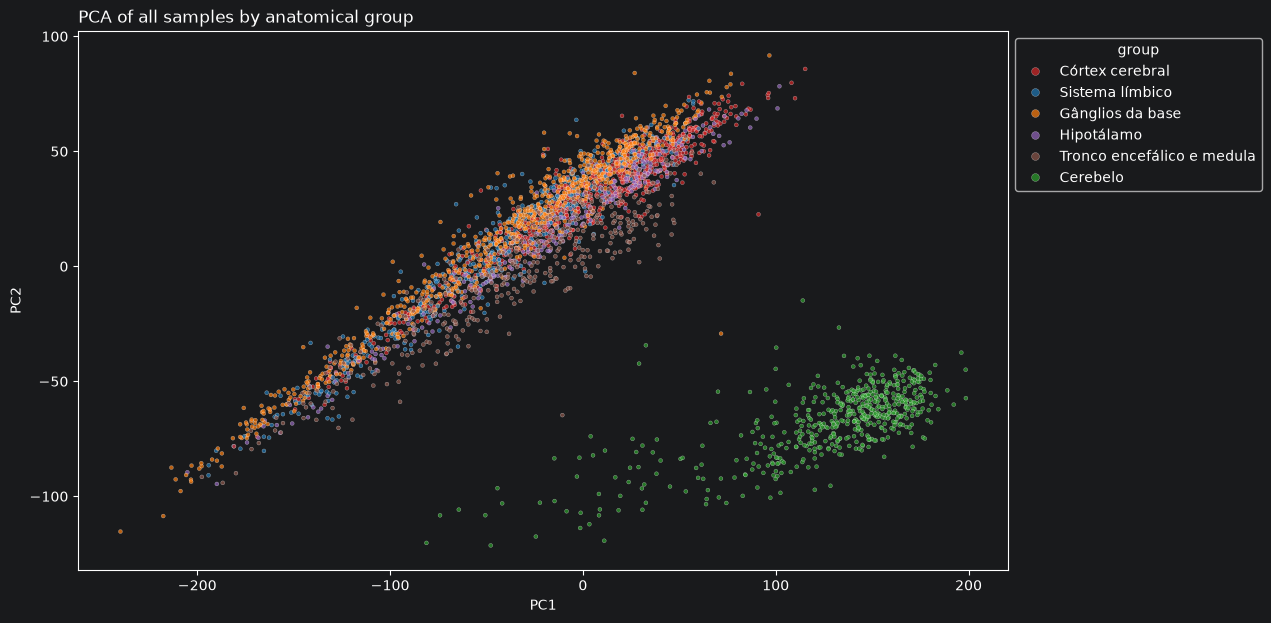

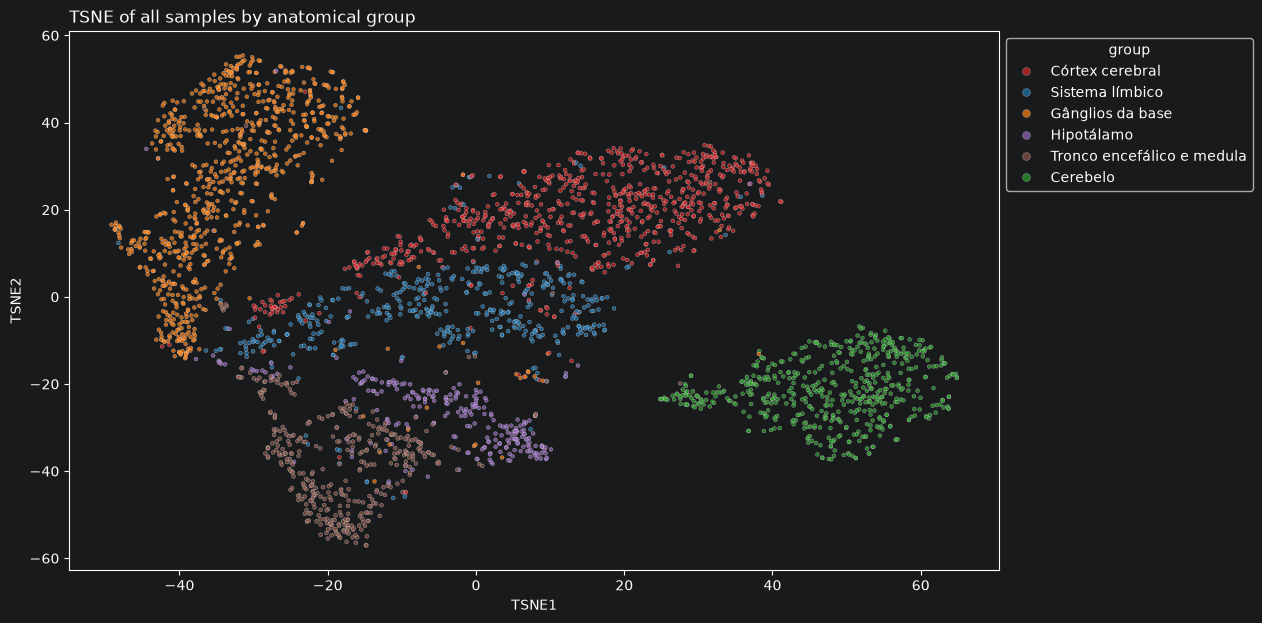

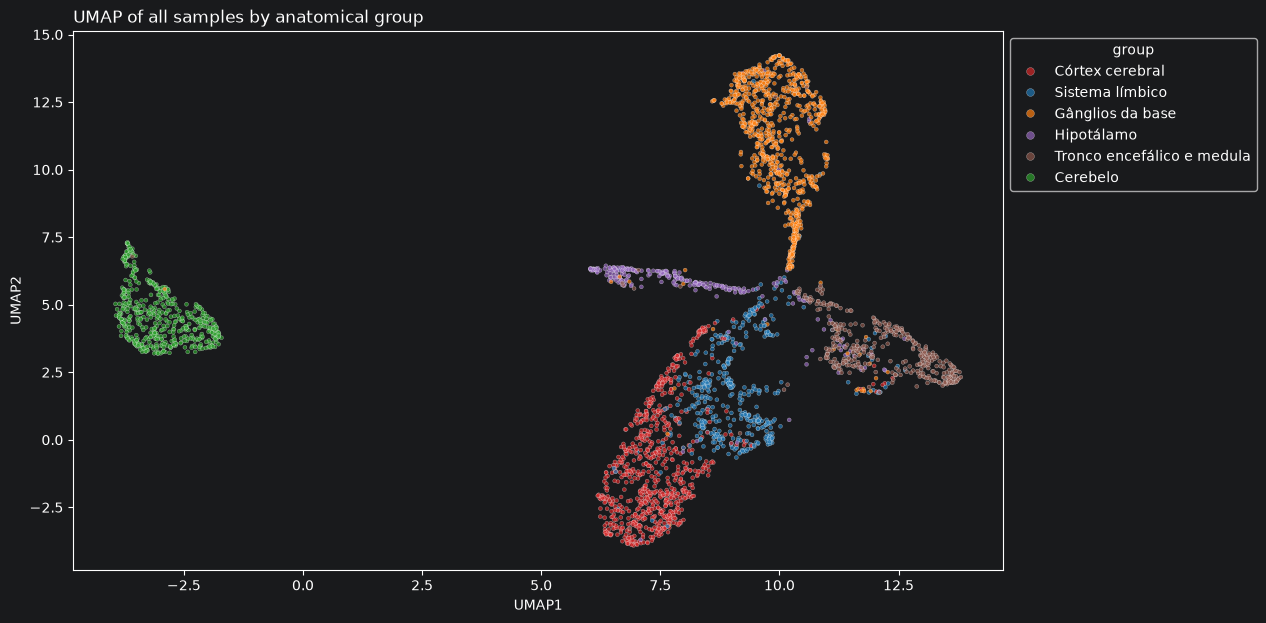

In [9]:
region_group = dict(zip(brain_regions["Região (GTEx)"], brain_regions["Grupo"].str.split(" ", n=1).str[1]))
projection["group"] = projection["region"].map(region_group)

group_colors = {
    "Córtex cerebral": "#d62728",
    "Sistema límbico": "#1f77b4",
    "Gânglios da base": "#ff7f0e",
    "Hipotálamo": "#9467bd",
    "Tronco encefálico e medula": "#8c564b",
    "Cerebelo": "#2ca02c",
}

for method, (x, y) in {"PCA": ("PC1", "PC2"), "TSNE": ("TSNE1", "TSNE2"), "UMAP": ("UMAP1", "UMAP2")}.items():
    plt.figure(figsize=(12, 7))
    sns.scatterplot(data=projection, x=x, y=y, hue="group", hue_order=list(group_colors), palette=group_colors, s=8, alpha=0.7)
    plt.title(f"{method} of all samples by anatomical group", loc="left")
    plt.legend(title="group", bbox_to_anchor=(1, 1), markerscale=2)
    plt.show()

Nos gráficos anteriores, as amostras foram coloridas pelos grupos anatômicos definidos na tabela. Em todas as três projeções (PCA, t-SNE e UMAP), as regiões que compartilham uma função ou uma localização no cérebro tendem a ficar próximas umas das outras. O cerebelo forma um agrupamento isolado, os gânglios da base ficam juntos, e o córtex e o sistema límbico ocupam áreas vizinhas.

Esse resultado indica que regiões funcionalmente relacionadas também têm perfis de expressão gênica parecidos, o que sustenta o agrupamento anatômico usado na tabela. Assim qualitativamente podemos dizer que os dados condizem com a realidade.

In [10]:
sample_info = pd.DataFrame({
    "region": projection["region"].values,
    "group": projection["group"].values,
    "SEX": projection["SEX"].values,
    "AGE": donors.map(df.set_index("SUBJID")["AGE"]),
}, index=expression.index)

sample_info["age_group"] = sample_info["AGE"].replace({
    "20-29": "20-49", "30-39": "20-49", "40-49": "20-49",
    "60-69": "60-79", "70-79": "60-79",
})

variability_by_region = expression.groupby(sample_info["region"].values).std()
region_order = variability_by_region.median(axis=1).sort_values().index

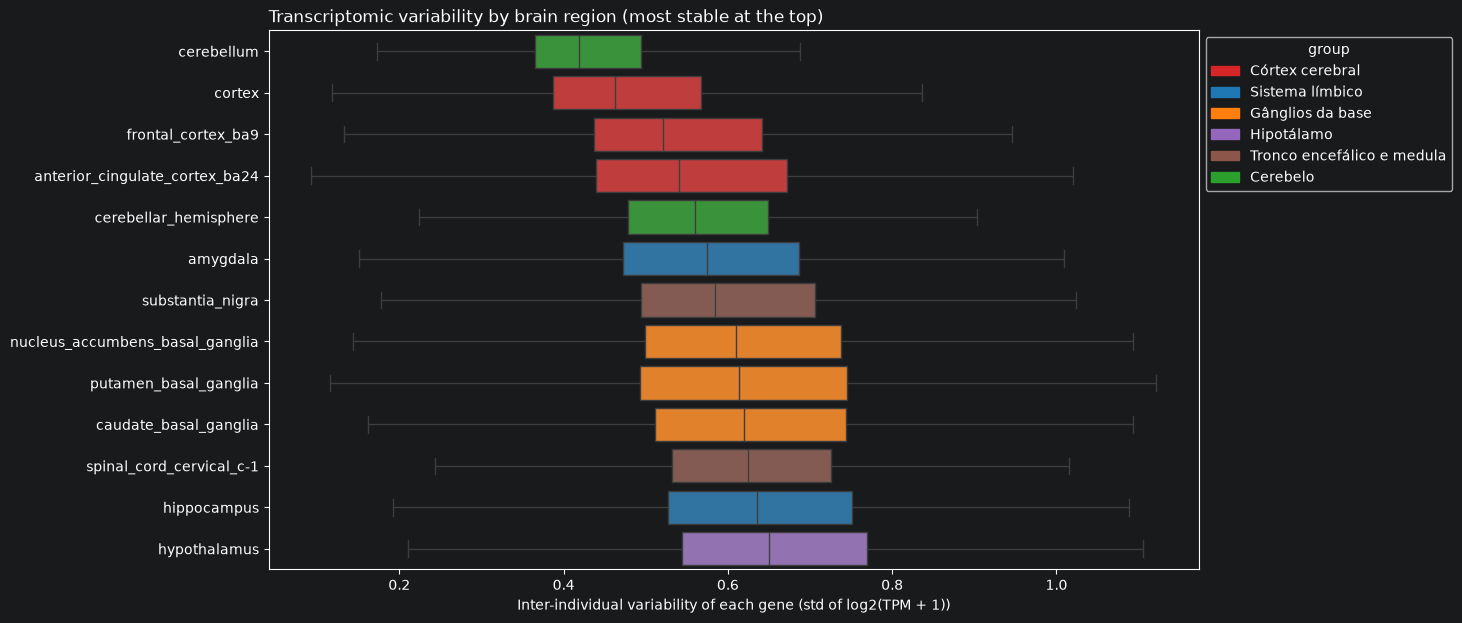

In [11]:
variability_long = variability_by_region.T.melt(var_name="region", value_name="variability")
region_colors = {region: group_colors[region_group[region]] for region in region_order}

plt.figure(figsize=(12, 7))
sns.boxplot(data=variability_long, x="variability", y="region", order=region_order,
            hue="region", palette=region_colors, legend=False, showfliers=False)
plt.xlabel("Inter-individual variability of each gene (std of log2(TPM + 1))")
plt.ylabel("")
plt.title("Transcriptomic variability by brain region (most stable at the top)", loc="left")
plt.legend(
    handles=[plt.Rectangle((0, 0), 1, 1, color=color) for color in group_colors.values()],
    labels=list(group_colors), title="group", bbox_to_anchor=(1, 1),
)
plt.show()

As regiões do cérebro não variam da mesma forma entre as pessoas. O cerebelo é a região mais estável, com a menor mediana de variabilidade, e o hipotálamo é a mais variável. As três regiões do córtex também ficam entre as mais estáveis, enquanto os gânglios da base, o hipocampo e a medula espinhal ficam entre as mais variáveis.

Essa diferença é moderada. As caixas das regiões se sobrepõem bastante, o que mostra que a variabilidade de cada região é parecida em ordem de grandeza e que os genes de uma mesma região variam muito entre si. Além disso, o cerebelo e o hemisfério cerebelar, que são duplicatas da mesma região no GTEx, ficam em posições diferentes, o que sugere que parte da variabilidade pode vir de diferenças técnicas na coleta e na preservação das amostras.


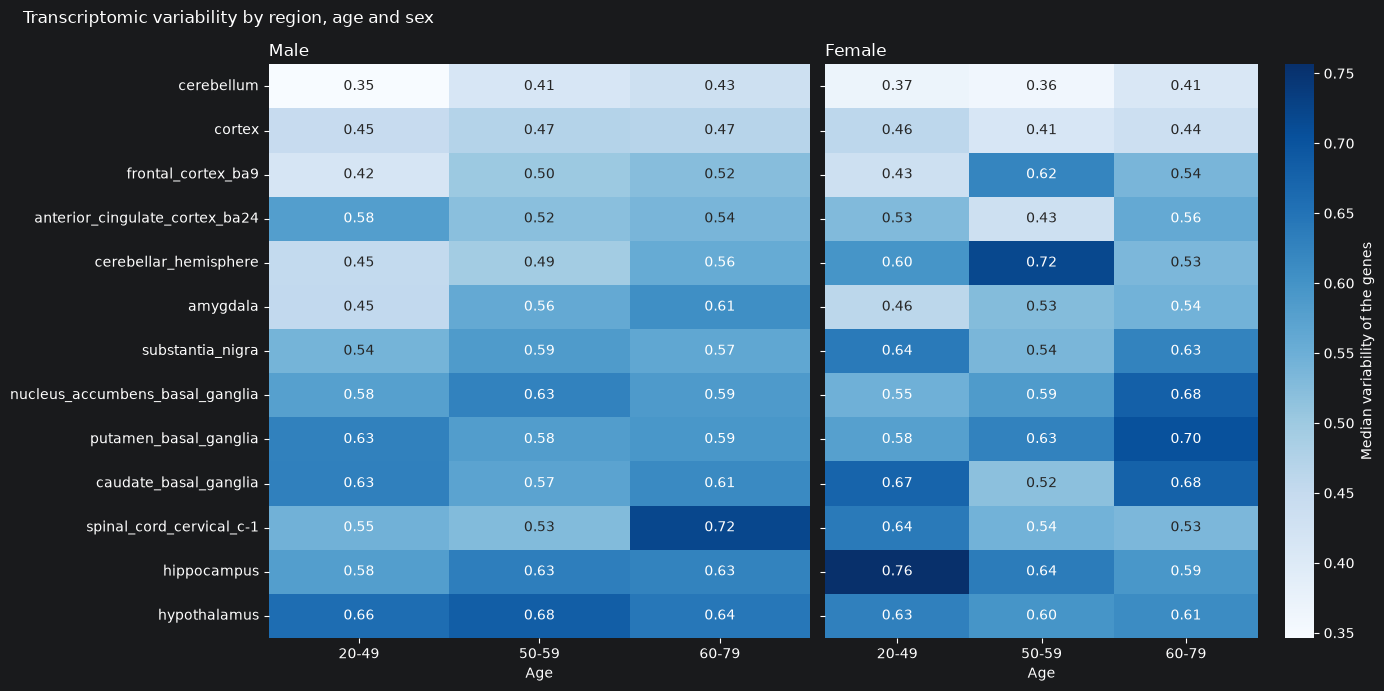

age_group                               20-49  50-59  60-79
region                          SEX                        
amygdala                        Female      9     14     29
                                Male       14     43     72
anterior_cingulate_cortex_ba24  Female     12     14     30
                                Male       27     48    102
caudate_basal_ganglia           Female     16     21     39
                                Male       30     65    129
cerebellar_hemisphere           Female     15     21     39
                                Male       26     67    109
cerebellum                      Female     13     17     42
                                Male       28     64    102
cortex                          Female     13     22     40
                                Male       27     62    106
frontal_cortex_ba9              Female     12     20     36
                                Male       24     63    114
hippocampus                     Female     12     22     31
                                Male       25     53    112
hypothalamus                    Female     10     20     34
                                Male       23     62    108
nucleus_accumbens_basal_ganglia Female     14     21     38
                                Male       26     67    119
putamen_basal_ganglia           Female      9     19     33
                                Male       26     63    104
spinal_cord_cervical_c-1        Female     12     21     35
                                Male       15     40     81
substantia_nigra                Female     12     16     22
                                Male       15     35     83

In [12]:
variability_by_age_sex = (
    expression
    .groupby([sample_info["region"].values, sample_info["SEX"].values, sample_info["age_group"].values])
    .std()
    .median(axis=1)
    .unstack()
)

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharey=True)
for ax, sex in zip(axes, ["Male", "Female"]):
    sns.heatmap(
        variability_by_age_sex.xs(sex, level=1).loc[region_order], ax=ax,
        annot=True, fmt=".2f", cmap="Blues",
        vmin=variability_by_age_sex.min().min(), vmax=variability_by_age_sex.max().max(),
        cbar=ax is axes[1], cbar_kws={"label": "Median variability of the genes"},
    )
    ax.set_title(sex, loc="left")
    ax.set_xlabel("Age")
    ax.set_ylabel("")
fig.suptitle("Transcriptomic variability by region, age and sex", x=0.02, ha="left")
plt.tight_layout()
plt.show()

sample_info.groupby(["region", "SEX", "age_group"]).size().unstack()

Neste gráfico, quis comparar homens e mulheres quanto à variação da expressão gênica entre as pessoas, em cada região do cérebro e em cada faixa etária. Para cada região, o mapa de calor mostra a variabilidade mediana dos genes separada por sexo e por idade, e a tabela abaixo dele traz o número de amostras de cada grupo.

O principal resultado é uma limitação dos dados. As mulheres têm bem menos amostras do que os homens: os grupos femininos têm entre 9 e 42 amostras, e os masculinos entre 14 e 129. Por isso, as variabilidades dos dois sexos não são igualmente confiáveis, e um desvio padrão calculado com poucas amostras oscila mais ao acaso. Com os grupos femininos tão pequenos, não conseguimos dizer se a variabilidade continua aumentando com a idade nas mulheres, como parece acontecer em algumas regiões nos homens. Nas mulheres, o padrão é irregular e pode refletir apenas o tamanho reduzido da amostra.

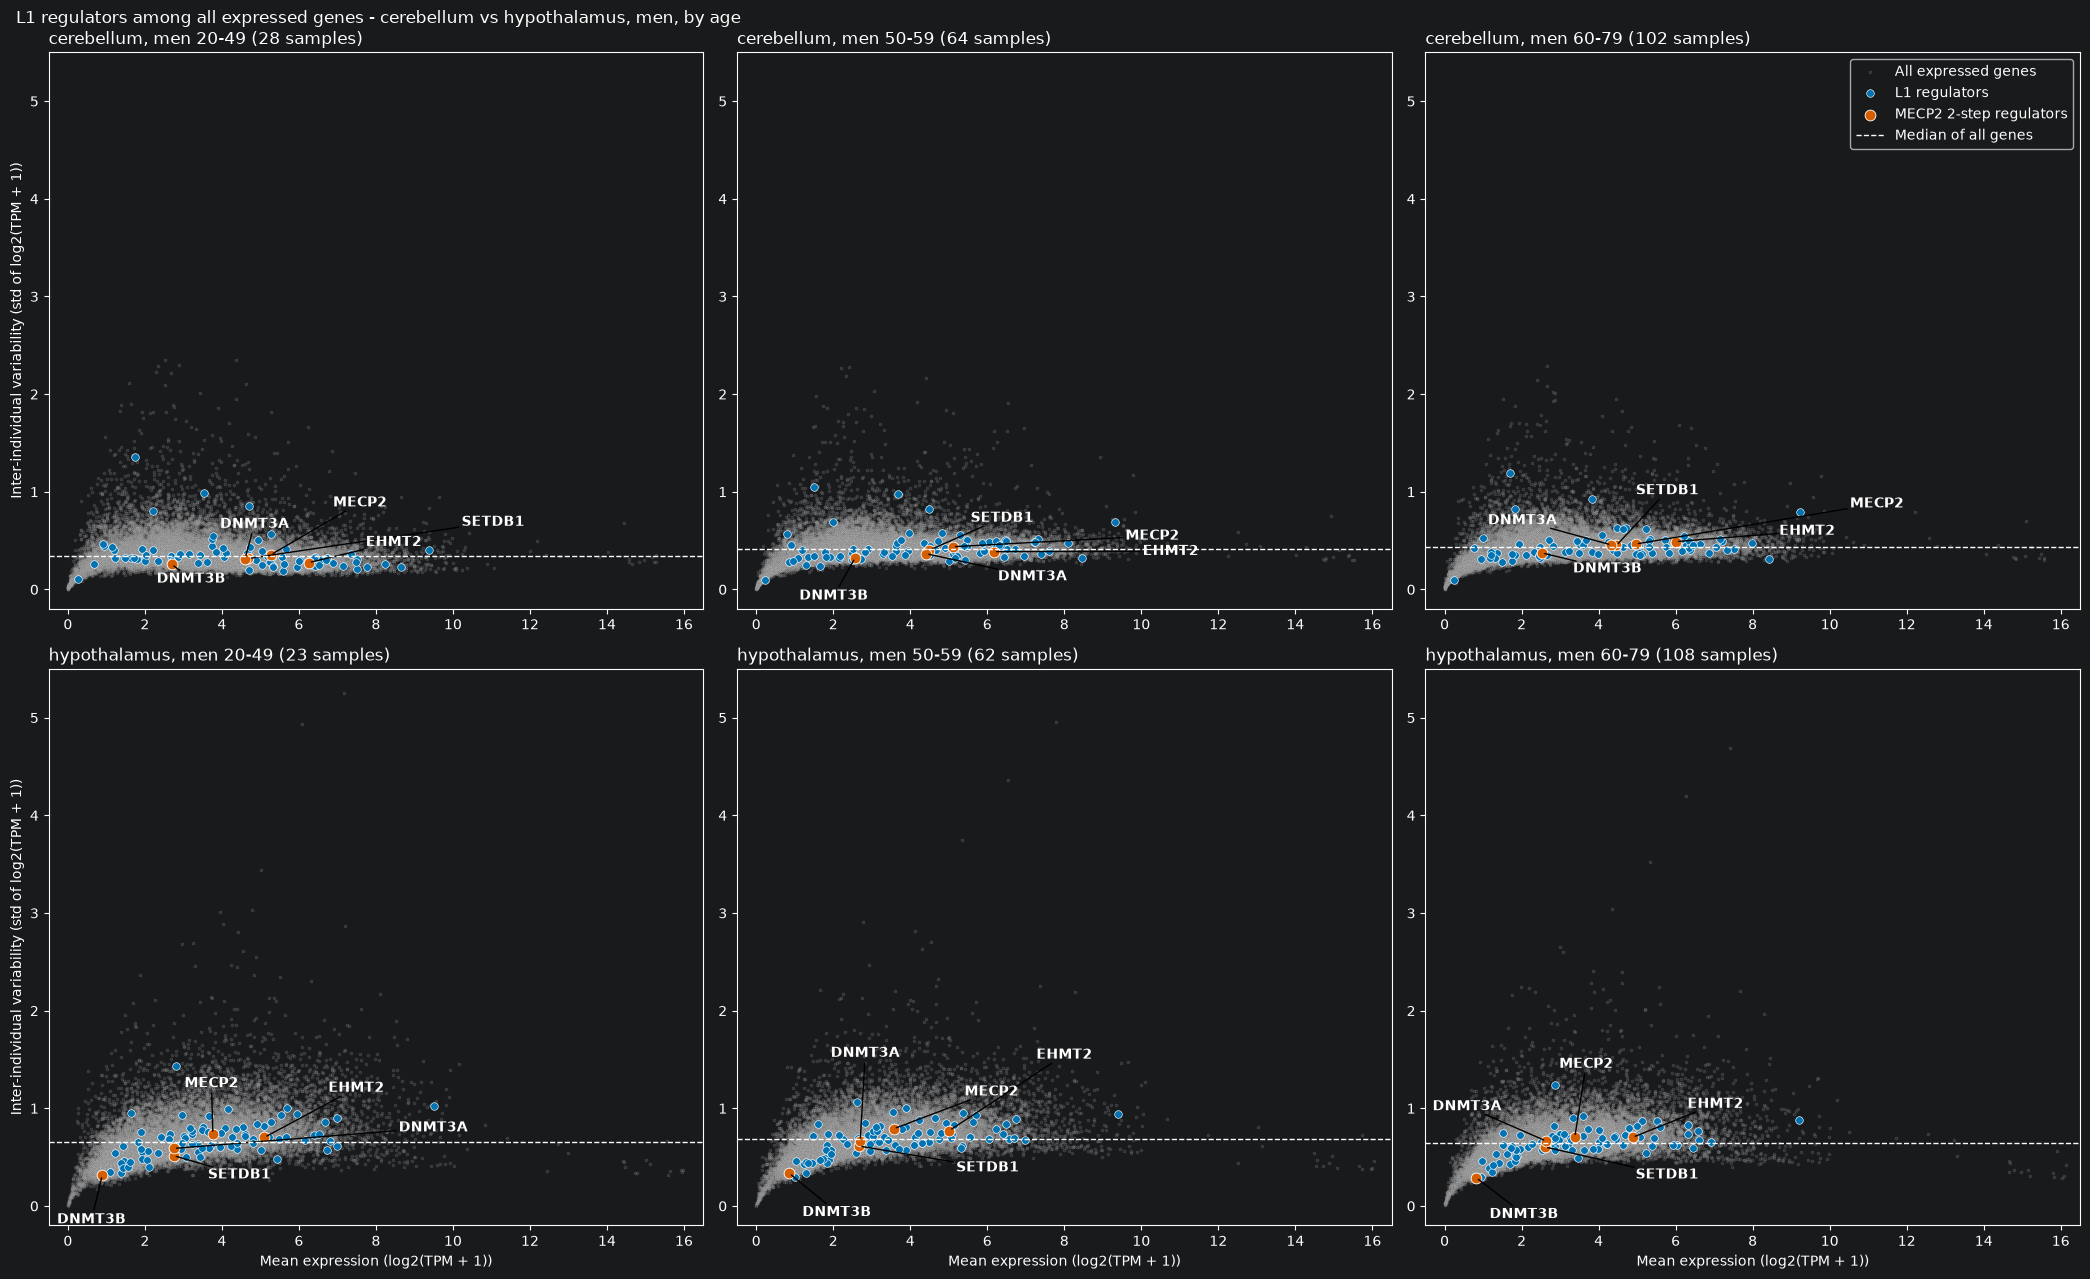

In [13]:
gene_symbols = regions[BrainRegions.CORTEX].set_index("Name")["Description"]
compared_regions = ["cerebellum", "hypothalamus"]
age_groups = ["20-49", "50-59", "60-79"]

men = sample_info["SEX"] == "Male"

fig, axes = plt.subplots(len(compared_regions), len(age_groups), figsize=(21, 13), sharex=True, sharey=True)
for ax, (region, age_group) in zip(axes.flat, [(r, a) for r in compared_regions for a in age_groups]):
    region_expression = expression[(men & (sample_info["region"] == region) & (sample_info["age_group"] == age_group)).values]
    region_stats = pd.DataFrame({
        "symbol": gene_symbols[expression.columns].values,
        "mean": region_expression.mean().values,
        "variability": region_expression.std().values,
    })
    region_l1 = region_stats[region_stats["symbol"].isin(L1_REGULATORS)]
    region_mecp2 = region_stats[region_stats["symbol"].isin(L1_REGULATORS_WITH_2_STEPS_FROM_MECP2)]

    sns.scatterplot(data=region_stats, x="mean", y="variability", color="gray", s=5, alpha=0.25, label="All expressed genes", ax=ax)
    sns.scatterplot(data=region_l1, x="mean", y="variability", color="#0173b2", s=30, label="L1 regulators", ax=ax)
    sns.scatterplot(data=region_mecp2, x="mean", y="variability", color="#d55e00", s=60, label="MECP2 2-step regulators", ax=ax)
    texts = [ax.text(gene["mean"], gene["variability"], gene["symbol"], weight="bold") for _, gene in region_mecp2.iterrows()]
    adjust_text(texts, ax=ax, x=region_l1["mean"].values, y=region_l1["variability"].values,
                expand=(2, 2), force_text=(1, 1), force_static=(1, 1), arrowprops={"arrowstyle": "-", "color": "black"})
    ax.axhline(region_stats["variability"].median(), color="white", linestyle="--", linewidth=1, label="Median of all genes")
    ax.set_title(f"{region}, men {age_group} ({len(region_expression)} samples)", loc="left")
    ax.set_xlabel("Mean expression (log2(TPM + 1))")
    ax.set_ylabel("Inter-individual variability (std of log2(TPM + 1))")
    ax.legend().remove()

for ax in axes.flat:
    ax.set_xlim(-0.5, 16.5)
    ax.set_ylim(-0.2, 5.5)
    ax.set_xticks(range(0, 17, 2))
    ax.set_yticks(range(0, 6))
    ax.tick_params(labelbottom=True, labelleft=True)
    if ax not in axes[-1]:
        ax.set_xlabel("")
    if ax not in axes[:, 0]:
        ax.set_ylabel("")

axes[0, -1].legend(bbox_to_anchor=(1, 1))
fig.suptitle("L1 regulators among all expressed genes - cerebellum vs hypothalamus, men, by age", x=0.01, ha="left")
plt.tight_layout()
plt.show()

Nestes gráficos, os reguladores de L1 (em azul) e os reguladores que possuiem relaçao de grau 2 com MECP2 (em laranja) ficam dentro da nuvem dos demais genes expressos, em alturas parecidas com as da maioria deles. Na maioria dos casos, eles não aparecem entre os genes de maior variabilidade entre as pessoas. Isso vale para o cerebelo e para o hipotálamo e se repete nas três faixas de idade, e só alguns poucos reguladores aparecem isolados acima dos demais.

Esses gráficos comparam pessoas de faixas etárias diferentes em um único momento, e não acompanham as mesmas pessoas ao longo da vida. Por isso, o que podemos afirmar é que os reguladores não se destacam pela variabilidade entre indivíduos, e não que eles permanecem estáveis com o envelhecimento.